In [1]:
import pandas as pd
import torch

print("Pandas Version:", pd.__version__)
print("GPU Available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Using GPU:", torch.cuda.get_device_name(0))

Pandas Version: 2.2.2
GPU Available: False


In [8]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
a= {
    "name": "Rohan",
    "id": 122
}

a

{'name': 'Rohan', 'id': 122}

In [3]:
a.pop('id')
a

{'name': 'Rohan'}

# Libraries: Numpy, Pandas

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, OneHotEncoder, MinMaxScaler, LabelEncoder

In [9]:
data = pd.read_csv("/content/drive/MyDrive/DataSets/EDAEg/train_u6lujuX_CVtuZ9i.csv")

data.head(10)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
5,LP001011,Male,Yes,2,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,Y
6,LP001013,Male,Yes,0,Not Graduate,No,2333,1516.0,95.0,360.0,1.0,Urban,Y
7,LP001014,Male,Yes,3+,Graduate,No,3036,2504.0,158.0,360.0,0.0,Semiurban,N
8,LP001018,Male,Yes,2,Graduate,No,4006,1526.0,168.0,360.0,1.0,Urban,Y
9,LP001020,Male,Yes,1,Graduate,No,12841,10968.0,349.0,360.0,1.0,Semiurban,N


In [10]:
data.duplicated().sum()

np.int64(0)

In [11]:
x=data.iloc[[0, 3, 50, 500]]
data=pd.concat([data, x], ignore_index=True)
data.duplicated().sum()

np.int64(4)

In [12]:
data.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status'],
      dtype='object')

<function matplotlib.pyplot.show(close=None, block=None)>

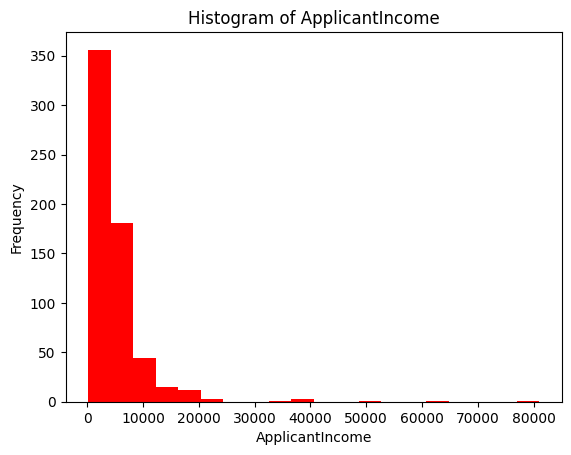

In [10]:
plt.hist(data['ApplicantIncome'], bins=20, color='red')
plt.xlabel('ApplicantIncome')
plt.ylabel('Frequency')
plt.title('Histogram of ApplicantIncome')
plt.show

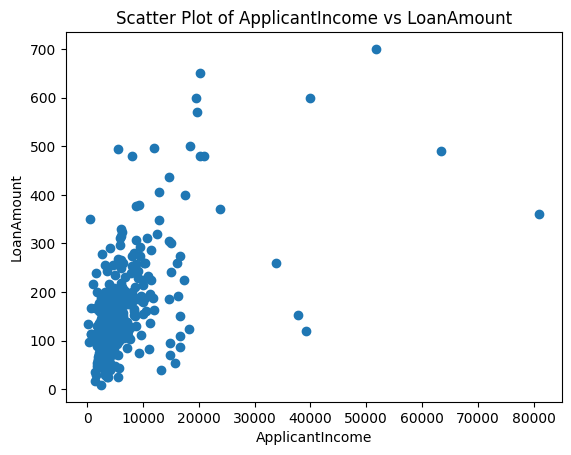

In [11]:
plt.scatter(data['ApplicantIncome'], data['LoanAmount'])
plt.xlabel('ApplicantIncome')
plt.ylabel('LoanAmount')
plt.title('Scatter Plot of ApplicantIncome vs LoanAmount')
plt.show()

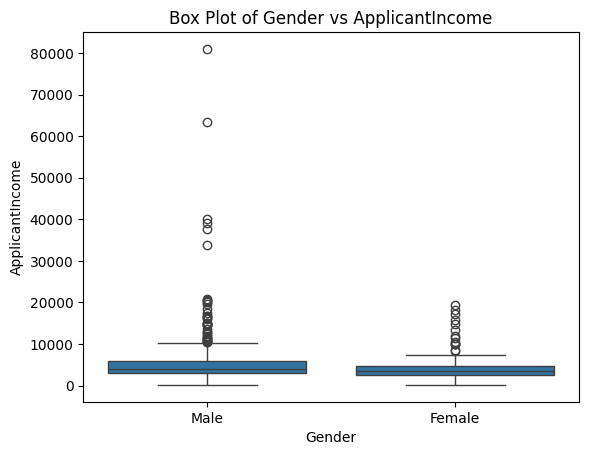

In [13]:
sns.boxplot(x='Gender', y='ApplicantIncome', data=data)
plt.xlabel('Gender')
plt.ylabel('ApplicantIncome')
plt.title('Box Plot of Gender vs ApplicantIncome')
plt.show()


In [14]:
data['Credit_History'].isnull().sum()

np.int64(50)

In [21]:
data['Credit_History'].fillna(data['Credit_History'].mode()[0], inplace=True)
data['Credit_History'].head(50)

,Credit_History
0,1.0
1,1.0
2,1.0
3,1.0
4,1.0
5,1.0
6,1.0
7,0.0
8,1.0
9,1.0


In [22]:
data['Credit_History'].isnull().sum()

np.int64(0)

In [23]:
data.duplicated().sum()

np.int64(4)

In [13]:
data.drop_duplicates(inplace=True)
data.head(50)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
5,LP001011,Male,Yes,2,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,Y
6,LP001013,Male,Yes,0,Not Graduate,No,2333,1516.0,95.0,360.0,1.0,Urban,Y
7,LP001014,Male,Yes,3+,Graduate,No,3036,2504.0,158.0,360.0,0.0,Semiurban,N
8,LP001018,Male,Yes,2,Graduate,No,4006,1526.0,168.0,360.0,1.0,Urban,Y
9,LP001020,Male,Yes,1,Graduate,No,12841,10968.0,349.0,360.0,1.0,Semiurban,N


In [27]:
data.duplicated().sum()

np.int64(0)

In [29]:
scaler = StandardScaler()
data['ApplicantIncome_scaled'] = scaler.fit_transform(data[['ApplicantIncome']])
display(data.head())

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,ApplicantIncome_scaled
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y,0.072991
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N,-0.134412
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y,-0.393747
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y,-0.462062
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y,0.097728


In [33]:
le = LabelEncoder()
data['Gender_encoded'] = le.fit_transform(data['Gender'])
display(data['Gender_encoded'].head())

,Gender_encoded
0,1
1,1
2,1
3,1
4,1
